 **problem Statement** : The objective of this project is to build a machine learning model that automatically classifies an email as Spam or Not Spam (Ham) based on its text content.

## Loading Data

In [2]:
!pip install wordcloud

In [3]:
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
from sklearn.feature_extraction.text import TfidfVectorizer


#from bs4 import BeautifulSoup
from wordcloud import WordCloud


from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


from sklearn.metrics import accuracy_score

In [4]:
data=pd.read_csv('spam.csv')

In [5]:
df=data.copy()

In [6]:
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
df.shape

(5572, 2)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [9]:
cols={'Category':'category','Message':'message'}
df.rename(columns=cols,inplace=True)

In [10]:
df['category'].value_counts()

category
ham     4825
spam     747
Name: count, dtype: int64

In [11]:
df.isnull().sum()

category    0
message     0
dtype: int64

In [12]:
df.duplicated().sum()

df=df.drop_duplicates()

Data visualization

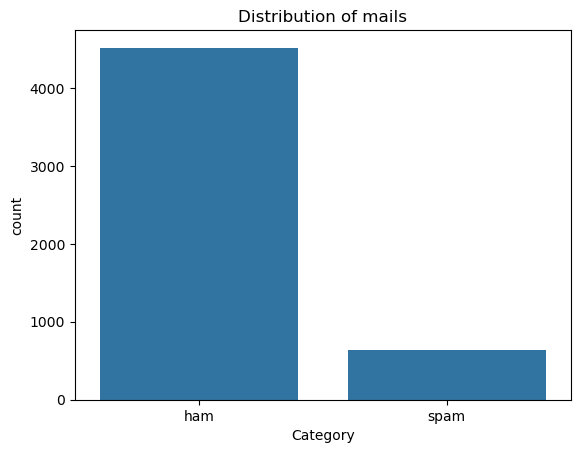

In [13]:
sns.countplot(x=df['category'])
plt.title('Distribution of mails')
plt.xlabel('Category')
plt.ylabel('count')
plt.show()

### **Data Preprocessing**

In [14]:
le=LabelEncoder()
df['category']=le.fit_transform(df['category'])
df.head()

,category,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [96]:
# def clean_data(text):
    
#     text = text.lower()
    
#     text = text.strip()

#     text = BeautifulSoup(text, 'html.parser').get_text()
    
#     text = re.sub(r'http\S+|www\S+', '', text)

#     text = re.sub(r"<.*?>", "", text)

#     text = re.sub(r'[^a-zA-Z\s]', '', text)

#     text = re.sub(r'\s+', ' ', text)

#     return text

In [15]:
def clean_data(text):
    text = text.lower()
    text = text.strip()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Keep only letters and spaces
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text)

    return text

In [16]:
df['message']=df['message'].apply(clean_data)

In [17]:
# input output seperation

X=df['message']
y=df['category']

In [18]:
# splitting data into X_train,y_train x_test,y_test

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)

In [19]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4125,)
(1032,)
(4125,)
(1032,)


### **TF-IDF**

In [20]:
vectorizer=TfidfVectorizer(lowercase=True,
                           stop_words='english',
                           max_features=5000,
                           ngram_range=(1,2),
                           min_df=2,
                           max_df=0.95)

In [21]:
# multinaive bayes algorithm

# pipeline

naive_bayes_pipe=Pipeline([('tf-idf',vectorizer),('model',MultinomialNB(alpha=0.1))])
naive_bayes_pipe.fit(X_train,y_train)


Pipeline(steps=[('tf-idf',
                 TfidfVectorizer(max_df=0.95, max_features=5000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english')),
                ('model', MultinomialNB(alpha=0.1))])

In [22]:
#Logistic Regression

logistic_pipe=Pipeline([('tf-idf',vectorizer),('logistic_model',LogisticRegression())])
logistic_pipe.fit(X_train,y_train)

Pipeline(steps=[('tf-idf',
                 TfidfVectorizer(max_df=0.95, max_features=5000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english')),
                ('logistic_model', LogisticRegression())])

In [23]:
# Decision Tree classifier

decision_pipe=Pipeline([('tf-idf',vectorizer),('decision_tree',DecisionTreeClassifier())])
decision_pipe.fit(X_train,y_train)

Pipeline(steps=[('tf-idf',
                 TfidfVectorizer(max_df=0.95, max_features=5000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english')),
                ('decision_tree', DecisionTreeClassifier())])

In [24]:
#Random Forest classifier

random_forest_pipe=Pipeline([('tf-idf',vectorizer),('Rforest',RandomForestClassifier())])
random_forest_pipe.fit(X_train,y_train)

Pipeline(steps=[('tf-idf',
                 TfidfVectorizer(max_df=0.95, max_features=5000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english')),
                ('Rforest', RandomForestClassifier())])

### **Evaluation**

In [25]:
from sklearn.metrics import accuracy_score

models = {
    'naive_bayes': naive_bayes_pipe,
    'logistic_regression': logistic_pipe,
    'Decision_tree': decision_pipe,
    'Random_Forest': random_forest_pipe
}


def calculate_accuracy(model_name, model, X_test, y_test):
    
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    return f"{model_name}\n Accuracy: {acc}"


for model_name, model in models.items():
    print(calculate_accuracy(model_name, model, X_test, y_test))   

naive_bayes
 Accuracy: 0.9806201550387597
logistic_regression
 Accuracy: 0.9534883720930233
Decision_tree
 Accuracy: 0.9467054263565892
Random_Forest
 Accuracy: 0.9718992248062015


### **HyperParameter Tuning**

In [26]:
from sklearn.model_selection import GridSearchCV


param_grid = {
    'tf-idf__max_features': [3000, 5000, 8000],
    'tf-idf__min_df': [1, 2, 3],
    'tf-idf__ngram_range': [(1, 1), (1, 2)],
    'model__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
}

gird=GridSearchCV(naive_bayes_pipe,
                 param_grid,
                 cv=5,
                 scoring='accuracy',
                 verbose=True,
                  n_jobs=-1
                 )
gird.fit(X_train,y_train)

Fitting 5 folds for each of 90 candidates, totalling 450 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('tf-idf',
                                        TfidfVectorizer(max_df=0.95,
                                                        max_features=5000,
                                                        min_df=2,
                                                        ngram_range=(1, 2),
                                                        stop_words='english')),
                                       ('model', MultinomialNB(alpha=0.1))]),
             n_jobs=-1,
             param_grid={'model__alpha': [0.01, 0.1, 0.5, 1.0, 2.0],
                         'tf-idf__max_features': [3000, 5000, 8000],
                         'tf-idf__min_df': [1, 2, 3],
                         'tf-idf__ngram_range': [(1, 1), (1, 2)]},
             scoring='accuracy', verbose=True)

In [31]:
gird.best_params_

{'model__alpha': 0.1,
 'tf-idf__max_features': 5000,
 'tf-idf__min_df': 2,
 'tf-idf__ngram_range': (1, 2)}

In [32]:
gird.best_score_

np.float64(0.9791515151515151)

In [33]:
gird.best_estimator_

Pipeline(steps=[('tf-idf',
                 TfidfVectorizer(max_df=0.95, max_features=5000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english')),
                ('model', MultinomialNB(alpha=0.1))])

In [34]:
best_model=gird.best_estimator_

y_pred=best_model.predict(X_test)

score=accuracy_score(y_test,y_pred)

In [35]:
score

0.9806201550387597

In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       893
           1       0.98      0.88      0.92       139

    accuracy                           0.98      1032
   macro avg       0.98      0.94      0.96      1032
weighted avg       0.98      0.98      0.98      1032



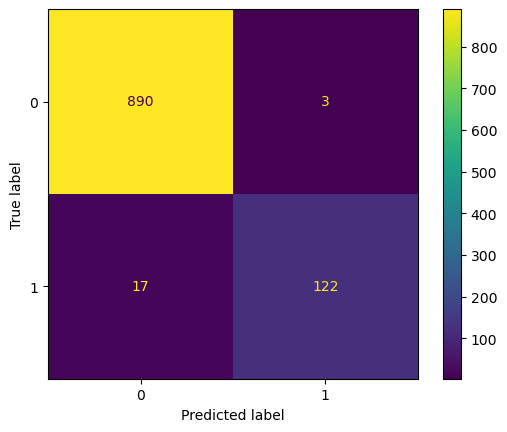

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm).plot()

plt.show()

In [39]:
import joblib

joblib.dump(best_model,'Email_spam_model.pkl')

['Email_spam_model.pkl']

In [40]:
model=joblib.load('Email_spam_model.pkl')

In [200]:
email=["congratulations you have won the lottery"]
result=model.predict(email)
print(result)

if result[0]==1:
    print('spam')
else:
    print('not Spam')


[1]
spam


In [41]:
email=["congratulations you have selected for test"]
result=model.predict(email)
print(result)

if result[0]==1:
    print('spam')
else:
    print('not Spam')

[0]
not Spam
